In [479]:
import pandas as pd
import numpy as np
import missingno as msno

In [480]:
df = pd.read_csv(r'/home/ziyad/Desktop/IA_DATA_2026_2027/02_ISMO_COURS_ET_TP/Principale/analyse des donnees/project_groupe_exam/Student_Performance_raw.csv' , index_col=0)

In [481]:
df.head()

,race/ethnicity,parental level of education,lunch,test preparation course,math percentage,reading score percentage,writing score percentage,sex
108,group C,associate's degree,standard,none,0.71,0.82,0.72,F
183,group C,high school,standard,none,0.85,0.78,0.75,F
106,group D,associate's degree,standard,completed,NaN,0.76,0.76,F
107,group C,high school,free/reduced,completed,0.41,0.36,0.34,F
51,NaN,bachelor's degree,free/reduced,completed,0.58,0.63,0.58,F


In [482]:
df.dtypes

race/ethnicity                     str
parental level of education        str
lunch                              str
test preparation course            str
math percentage                float64
reading score percentage       float64
writing score percentage       float64
sex                                str
dtype: object

In [483]:
df.shape

(214, 8)

In [484]:
df = df.drop_duplicates()

In [485]:
df.shape

(200, 8)

In [486]:
pourcentage_des_manquante_avant = df.isnull().mean()*100

<Axes: >

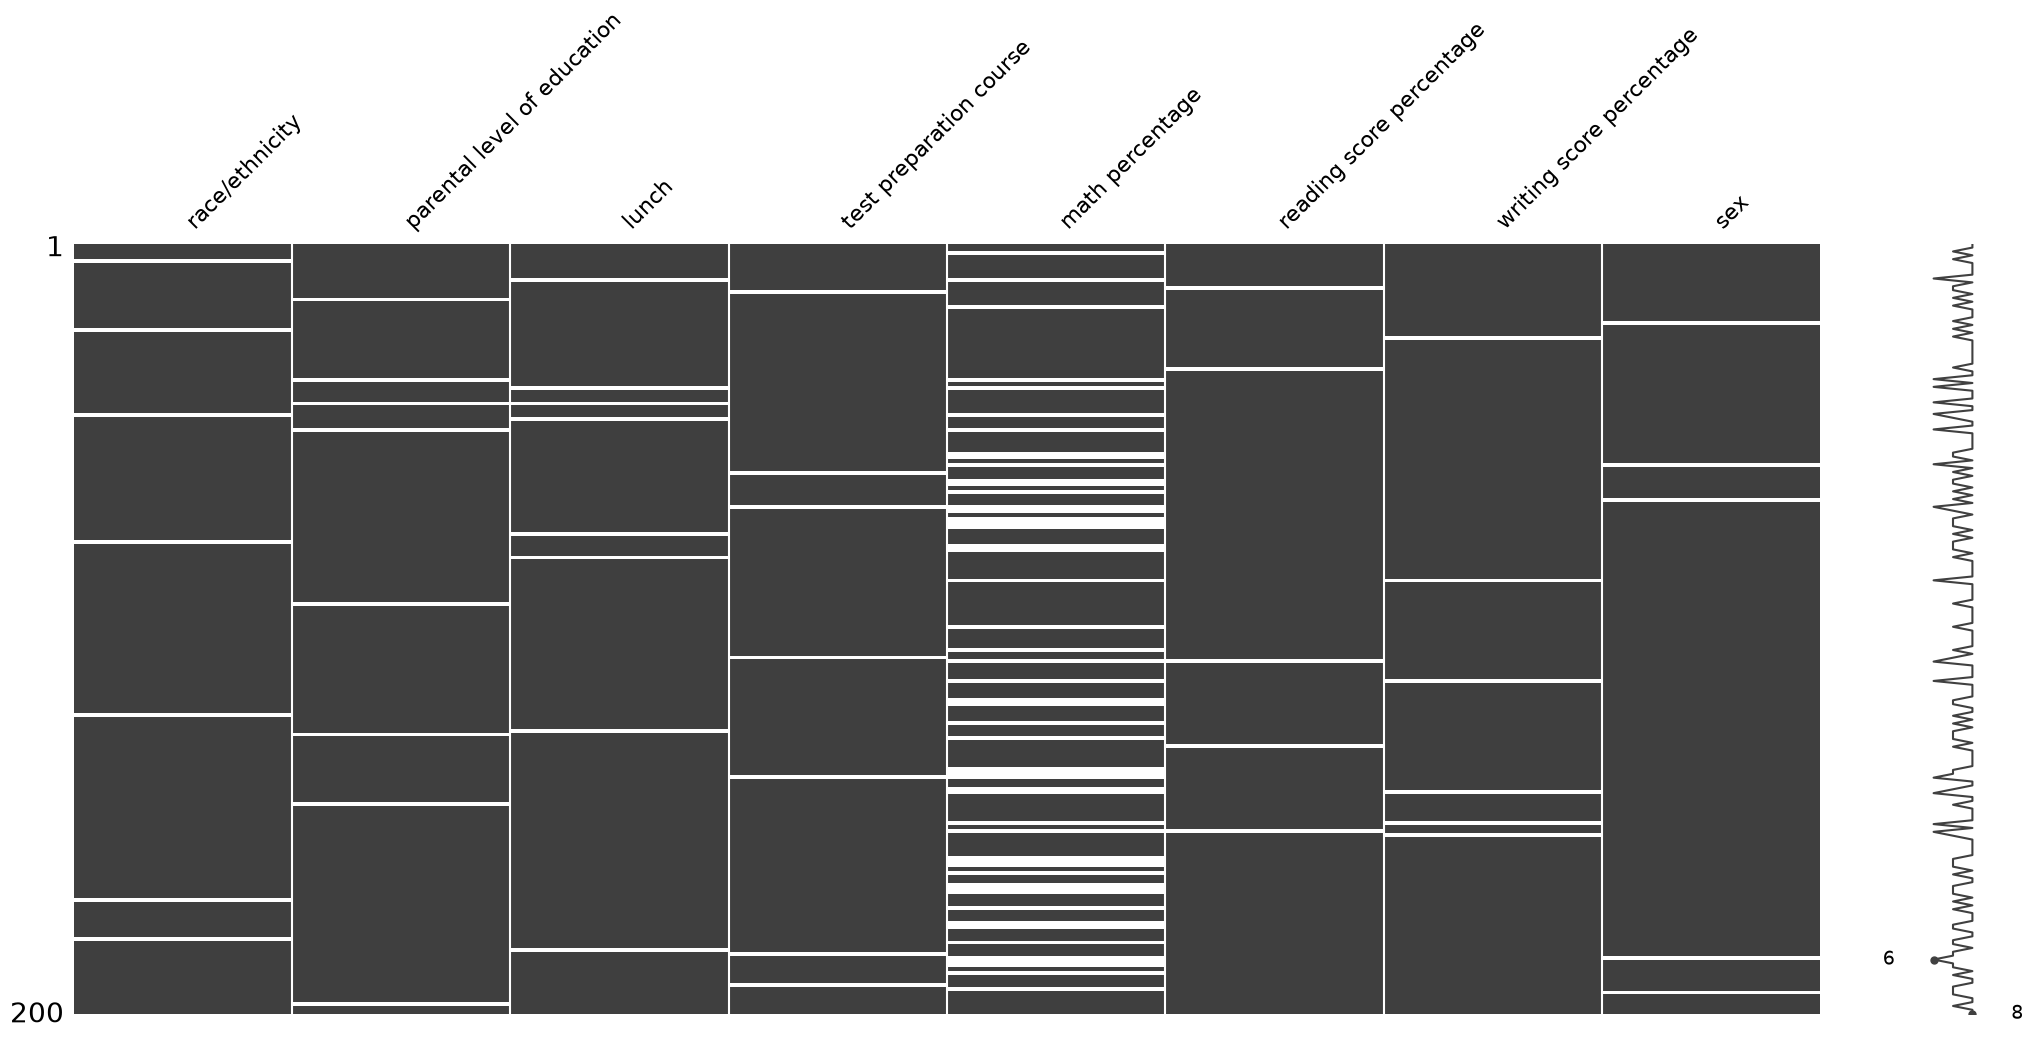

In [487]:
msno.matrix(df)

In [488]:
df_num = df.select_dtypes(include = 'number')
df_cat = df.select_dtypes(include = 'str')

In [489]:
df['sex'].value_counts()

sex
F         98
M         95
Female     1
X          1
Name: count, dtype: int64

In [490]:
df['sex'] = df['sex'].str.replace('Female' , 'F')
df['sex'] = df['sex'].replace('X' , np.nan)
df['sex'].value_counts()

sex
F    99
M    95
Name: count, dtype: int64

In [491]:
df[['math percentage', 'reading score percentage', 'writing score percentage']].agg(['min' , 'max'])

,math percentage,reading score percentage,writing score percentage
min,-0.3,-0.15,0.0
max,5.6,2.10,9.9


In [492]:
resultat = []
for i in df_num:
    q1 , q3 = df_num[i].quantile([0.25,0.75])
    iqr = q3 - q1
    bas, haut = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = df_num[(df_num[i] < bas) | (df_num[i] > haut)][i]
    resultat.append({"colonne": i, "borne_basse": bas,
                   "borne_haute": haut, "nb_aberrantes": len(out)})
print(pd.DataFrame(resultat))

                    colonne  borne_basse  borne_haute  nb_aberrantes
0           math percentage       0.2725       1.0525              3
1  reading score percentage       0.3000       1.1000              3
2  writing score percentage       0.3200       1.0400              3


In [493]:
score_cols = ['math percentage', 'reading score percentage', 'writing score percentage']
for col in score_cols:
    nb_outliers = ((df[col] <= 0) | (df[col] > 1)).sum()
    print(f"Nombre de valeurs aberrantes dans '{col}' : {nb_outliers}")

Nombre de valeurs aberrantes dans 'math percentage' : 3
Nombre de valeurs aberrantes dans 'reading score percentage' : 2
Nombre de valeurs aberrantes dans 'writing score percentage' : 3


In [494]:
for col in score_cols:
    df.loc[(df[col] < 0) | (df[col] > 1), col] = np.nan

In [495]:
df[['math percentage', 'reading score percentage', 'writing score percentage']].agg(['min' , 'max'])

,math percentage,reading score percentage,writing score percentage
min,0.36,0.29,0.0
max,1.00,1.00,1.0


In [496]:
pourcentage_des_manquante_apres = df.isnull().mean()*100

In [497]:
pd.concat([pourcentage_des_manquante_avant , pourcentage_des_manquante_apres] , axis = 1 , 
          keys = ['pourcentage des manquante avant traitement des valeurs aberrantes' ,'pourcentage des manquante apres traitement des valeurs aberrantes'] )

,pourcentage des manquante avant traitement des valeurs aberrantes,pourcentage des manquante apres traitement des valeurs aberrantes
race/ethnicity,3.5,3.5
parental level of education,4.0,4.0
lunch,4.0,4.0
test preparation course,3.5,3.5
math percentage,26.0,27.5
reading score percentage,2.5,3.5
writing score percentage,3.0,4.0
sex,2.5,3.0


In [498]:
missing_pct = df.select_dtypes(include='number').isnull().mean() * 100
print("Pourcentage de valeurs manquantes par colonne :\n", missing_pct)

Pourcentage de valeurs manquantes par colonne :
 math percentage             27.5
reading score percentage     3.5
writing score percentage     4.0
dtype: float64


In [499]:
score_cols = ['reading score percentage', 'writing score percentage']
for i in score_cols:
    skewness = df[i].skew()
    if -0.5 <= skewness <= 0.5:
        df[i] = df[i].fillna(df[i].mean())
    else :
        df[i] = df[i].fillna(df[i].median())


In [500]:
df.dtypes

race/ethnicity                     str
parental level of education        str
lunch                              str
test preparation course            str
math percentage                float64
reading score percentage       float64
writing score percentage       float64
sex                                str
dtype: object

In [501]:
categorie = ['race/ethnicity' , 'parental level of education' , 'lunch' , 'test preparation course' , 'sex']
for i in categorie:
    mode = df[i].mode()[0]
    df[i] = df[i].fillna(mode)

In [502]:
df.isnull().sum()

race/ethnicity                  0
parental level of education     0
lunch                           0
test preparation course         0
math percentage                55
reading score percentage        0
writing score percentage        0
sex                             0
dtype: int64

In [503]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
score_cols = ['math percentage', 'reading score percentage', 'writing score percentage']
scaler = StandardScaler()
df_scaled = df.copy()
df_scaled[score_cols] = scaler.fit_transform(df[score_cols])
model = KNNImputer(n_neighbors=5)
df_scaled[score_cols] = model.fit_transform(df_scaled[score_cols])

df_clean = df_scaled.copy()
df_clean[score_cols] = scaler.inverse_transform(df_scaled[score_cols])

In [504]:
df.describe()

,math percentage,reading score percentage,writing score percentage
count,145.000000,200.000000,200.000000
mean,0.669517,0.697720,0.680885
std,0.146013,0.148124,0.151425
min,0.360000,0.290000,0.000000
25%,0.570000,0.600000,0.590000
50%,0.670000,0.697720,0.680885
75%,0.760000,0.792500,0.760000
max,1.000000,1.000000,1.000000


In [505]:
ordre = {"some high school": 0, "high school": 1, "some college": 2,
         "associate's degree": 3, "bachelor's degree": 4, "master's degree": 5}

df_clean["parental level of education"] = df_clean["parental level of education"].map(ordre)
df_scaled["parental level of education"] = df_scaled["parental level of education"].map(ordre)

df_clean_enc = pd.get_dummies(df_clean, drop_first=True, dtype=int)
df_scaled_enc = pd.get_dummies(df_scaled, drop_first=True, dtype=int)

In [509]:
import matplotlib.pyplot as plt
import seaborn as sns
df_plot = df_clean.copy()

In [511]:
df_plot["score moyen"] = df_plot[score_cols].mean(axis=1)
df_enc = df_clean_enc.copy()
df_enc["score moyen"] = df_enc[score_cols].mean(axis=1)

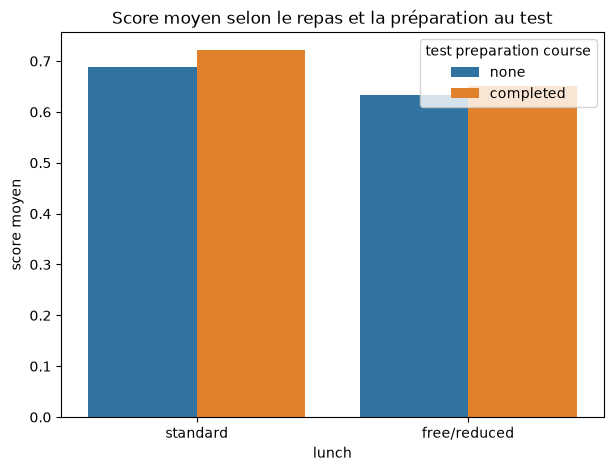

In [512]:
plt.figure(figsize=(7, 5))
sns.barplot(data=df_plot, x="lunch", y="score moyen",
            hue="test preparation course", errorbar=None)
plt.title("Score moyen selon le repas et la préparation au test")
plt.show()

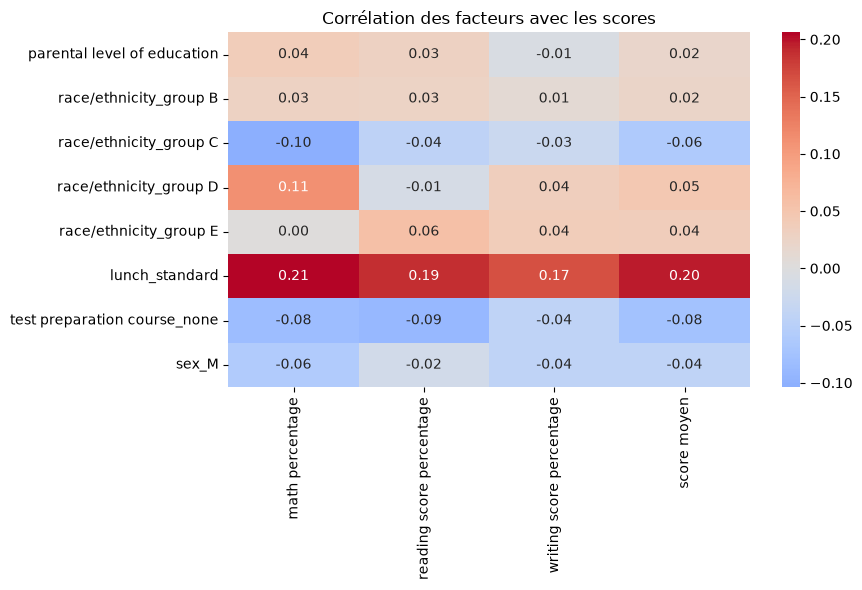

In [513]:
facteurs = [c for c in df_enc.columns if c not in score_cols + ["score moyen"]]
corr = df_enc.corr().loc[facteurs, score_cols + ["score moyen"]]

plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Corrélation des facteurs avec les scores")
plt.tight_layout()
plt.show()